# Traditional ML Biometric Verification
One notebook, plain functions, and one visible pipeline at a time. Open the separate **02_Streamlit_Demo.ipynb** for the application.

**Educational virtual identities:** the supplied face, public speaker, and public finger assigned to one user belong to unrelated physical people. This is not genuine same-person multimodal authentication. No deep learning, pretrained recognition embeddings, or speech-to-text service is used.

**Data path:** real files -> fixed train/validation/test splits -> traditional features -> training-only StandardScaler + PCA -> KNN or linear SVM.

**Protected path:** claimed identity -> face -> speaker -> face + voice feature fusion -> fingerprint -> three-modality feature fusion -> command -> permissions -> simulated action. Every failed gate stops the path.

Install requirements into the selected Python environment before Run All. The Python helpers are shared with the UI so the notebook and app cannot silently use different algorithms. Download plumbing stays in dataset_setup.py; the important ML functions are displayed below.

In [1]:
import sys
import json
import inspect
import subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Code, Audio, Image as DisplayImage
from config import ROOT, MANIFESTS, MODELS, LIVE
print('Python:', sys.executable)
print('Project:', ROOT)

Python: <project directory>\.venv\Scripts\python.exe
Project: <project directory>


## 1. Discover the Three People
**Input:** the original datasets/images folder. **Operation:** discover names, sort deterministically, assign user_01 to user_03. **Output:** the actual names and image counts. No original file is modified. A missing folder or a number of people other than three is an error.

In [2]:
from dataset_setup import discover_people, setup, validate_manifest
people = discover_people()
display(pd.DataFrame([{'user_id': user, 'display_name': folder.name,
    'image_files': len([path for path in folder.iterdir()
                        if path.suffix.lower() in {'.png', '.jpg', '.jpeg'}])}
    for user, folder in people.items()]))

,user_id,display_name,image_files
0,user_01,Abdelrahman,40
1,user_02,kareem,40
2,user_03,renad,40


## 2. Prepare Real Data and Freeze the Splits
**Input:** supplied images, Speech Commands v0.02, and official FVC2004 DB1_B. **Operation:** decode, reject corrupt/duplicate content, warn about similar photos, select one real speaker and finger per person, and split before training. **Output:** sample, virtual-identity, pair, triplet, and held-out demo manifests.

For 40 faces per person the split is 24/8/8. Each speaker has five distinct utterances for each of ON, OFF, GO, STOP, YES, NO: 3/1/1 per word. YES and NO become UNKNOWN for the command classifier. Fingerprints use 5/1/2 impressions per finger.

Speech uses local utterance-level partitions of enrolled speakers, not official Speech Commands benchmark partitions. A demo copy remains the same test observation, not an extra sample. Source decoding/hashes cannot prove separate photo capture sessions. Similar images can inflate results.

Leave REBUILD_DATA=False to preserve the prepared experiment. If downloading fails, the script reports BLOCKED; never substitute fake samples. Manual recovery is documented in DATASET_SOURCES.md.

In [3]:
REBUILD_DATA = False
if REBUILD_DATA or not (MANIFESTS / 'samples.csv').exists():
    setup(download=True)
samples = pd.read_csv(MANIFESTS / 'samples.csv', keep_default_na=False)
assert validate_manifest(samples)
display(samples.groupby(['modality', 'user_id', 'split']).size().unstack(fill_value=0))
identities = json.loads((MANIFESTS / 'identities.json').read_text(encoding='utf-8'))
display(pd.DataFrame(identities).T)
quality = json.loads((MANIFESTS / 'face_quality.json').read_text(encoding='utf-8'))
print('Near-duplicate warnings:', {row['person']: len(row['near_duplicate_pairs'])
                                  for row in quality['warnings']})
print('Corrupt/exact-duplicate exclusions:', quality['rejected'])
demo = pd.read_csv(LIVE / 'manifest.csv')
assert len(demo) == 3
display(demo[['user_id', 'display_name', 'original_speaker_id', 'original_finger_id', 'source_split']])

split                test  train  validation
modality    user_id                         
face        user_01     8     24           8
            user_02     8     24           8
            user_03     8     24           8
fingerprint user_01     2      5           1
            user_02     2      5           1
            user_03     2      5           1
voice       user_01     6     18           6
            user_02     6     18           6
            user_03     6     18           6

,display_name,role,face_identity,voice_identity,fingerprint_identity,virtual_identity
user_01,Abdelrahman,Admin,Abdelrahman,834f03fe,FVC2004_DB1_B:101,True
user_02,kareem,Employee,kareem,8e05039f,FVC2004_DB1_B:102,True
user_03,renad,Guest,renad,3bfd30e6,FVC2004_DB1_B:103,True


Near-duplicate warnings: {'Abdelrahman': 54, 'kareem': 2}
Corrupt/exact-duplicate exclusions: []


,user_id,display_name,original_speaker_id,original_finger_id,source_split
0,user_01,Abdelrahman,834f03fe,FVC2004_DB1_B:101,test
1,user_02,kareem,8e05039f,FVC2004_DB1_B:102,test
2,user_03,renad,3bfd30e6,FVC2004_DB1_B:103,test


## 3. Face Feature Pipeline
**Input:** RGB image. **Operation:** center-fit to 128 x 128; grayscale copy; HOG describes edges; normalized uniform LBP describes texture; three 256-bin histograms describe color. **Output:** one concatenated numerical vector.

HOG uses 9 orientations, 8 x 8 cells, and 2 x 2 blocks. LBP uses 8 neighbors, radius 1. The actual length is printed, not assumed. The displayed source is the same function used in the UI.

In [4]:
from features import load_image, hog_lbp, face_features, voice_features, fingerprint_features
display(Code(inspect.getsource(hog_lbp), language='python'))
display(Code(inspect.getsource(face_features), language='python'))
face_path = ROOT / samples[samples.modality.eq('face')].iloc[0]['path']
face_raw = face_features(face_path)
print('Face features:', face_raw.shape)
display(DisplayImage(filename=str(face_path), width=220))

def hog_lbp(gray):
    hog_vector = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                     cells_per_block=(2, 2), feature_vector=True)
    lbp_image = local_binary_pattern(gray, P=8, R=1, method="uniform")
    lbp_histogram = np.histogram(lbp_image, bins=np.arange(11), range=(0, 10))[0]
    lbp_histogram = lbp_histogram / max(lbp_histogram.sum(), 1)
    return np.concatenate([hog_vector, lbp_histogram]).astype(np.float32)

def face_features(source):
    rgb = load_image(source)
    gray = np.asarray(Image.fromarray(rgb).convert("L"))
    if gray.std() < 2:
        raise ValueError("Face image has almost no visible detail.")
    histograms = [np.histogram(rgb[:, :, channel], bins=256, range=(0, 256))[0]
                  / rgb.shape[0] / rgb.shape[1] for channel in range(3)]
    return np.concatenate([hog_lbp(gray), *histograms]).astype(np.float32)

Face features: (8878,)


## 4. Voice Feature Pipeline
**Input:** a real isolated-word recording. **Operation:** mono, 16 kHz, MFCC (13 coefficients), zero-crossing rate (ZCR), and RMS energy; mean and standard deviation across frames. **Output:** 13 + 13 + 1 + 1 + 1 + 1 = **30 values**. Empty, silent, corrupt, or excessively long audio is rejected.

Speaker identity and spoken word are different targets. Both classifiers use exactly the same extracted features; this is isolated-word classification, not general speech-to-text.

In [5]:
display(Code(inspect.getsource(voice_features), language='python'))
audio_path = ROOT / samples[samples.modality.eq('voice')].iloc[0]['path']
voice_raw = voice_features(audio_path)
assert voice_raw.shape == (30,)
print('Voice features:', voice_raw.shape)
display(Audio(filename=str(audio_path)))

def voice_features(source):
    samples = load_audio(source)
    mfcc = librosa.feature.mfcc(y=samples, sr=16000, n_mfcc=13,
                                n_fft=512, hop_length=160)
    zcr = librosa.feature.zero_crossing_rate(samples, frame_length=512, hop_length=160)
    rms = librosa.feature.rms(y=samples, frame_length=512, hop_length=160)
    vector = np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1),
                             zcr.mean(axis=1), zcr.std(axis=1),
                             rms.mean(axis=1), rms.std(axis=1)])
    if vector.shape != (30,) or not np.isfinite(vector).all():
        raise ValueError("Audio did not produce 30 finite traditional features.")
    return vector.astype(np.float32)

Voice features: (30,)


## 5. Fingerprint Feature Pipeline
**Input:** a genuine DB1_B impression. **Operation:** grayscale, center-fit/resize, HOG + normalized LBP. **Output:** one feature vector. Each virtual identity uses eight distinct impressions of one original finger. DB4_B is synthetic and is not used. No scanner or advanced minutiae algorithm is required.

In [6]:
display(Code(inspect.getsource(fingerprint_features), language='python'))
finger_path = ROOT / samples[samples.modality.eq('fingerprint')].iloc[0]['path']
print('Fingerprint features:', fingerprint_features(finger_path).shape)
display(DisplayImage(filename=str(finger_path), width=180))

def fingerprint_features(source):
    gray = load_image(source, mode="L")
    if gray.std() < 2:
        raise ValueError("Fingerprint image has almost no visible detail.")
    return hog_lbp(gray)

Fingerprint features: (8110,)


## 6. StandardScaler and PCA: Fit Only Training Data
**Input:** already separated raw feature vectors. **Operation:** fit StandardScaler and PCA on training rows only; transform validation/test with those fixed transforms. **Output:** smaller vectors preserving at least approximately 95% of training variance.

PCA does not use class labels, but fitting it on test data still leaks the test distribution. Split FIRST, fit SECOND. PCA whitening puts retained components on comparable training variance. Each modality block is divided by sqrt(number of retained features), so a longer face vector does not dominate voice purely by length. The same saved transformations are used in live inference.

In [7]:
from train import prepare_feature_data, task_data, train_models
display(Code(inspect.getsource(prepare_feature_data), language='python'))
preprocessors, vectors, dimensions = prepare_feature_data(samples)
display(pd.DataFrame(dimensions).T)
tasks = task_data(samples, vectors)
display(pd.DataFrame([{'task': task, 'train': len(splits['train'][1]),
    'validation': len(splits['validation'][1]), 'test': len(splits['test'][1]),
    'features': splits['train'][0].shape[1]} for task, splits in tasks.items()]))

def prepare_feature_data(frame):
    preprocessors, vectors, dimensions = {}, {}, {}
    for modality, extractor in EXTRACTORS.items():
        subset = frame[frame.modality == modality]
        if subset.empty:
            continue
        raw = np.asarray([extractor(ROOT / path) for path in subset.path], dtype=np.float32)
        training_mask = subset.split.eq("train").to_numpy()
        preprocessor = make_pipeline(StandardScaler(), PCA(n_components=0.95,
                                      svd_solver="full", whiten=True, random_state=SEED))
        preprocessor.fit(raw[training_mask])
        transformed = np.asarray([transform_features(preprocessor, row) for row in raw], dtype=np.float32)
        preprocessors[modality] = preprocessor
        vectors.update(zip(subset.sample_id, transformed))
        dimensions[modality] = {"raw": raw.shape[1], "after_pca": transformed.shape[1],
                                "pca_fit_samples": int(training_mask.sum()),
                                "variance_preserved": float(preprocessor[-1].explained_variance_ratio_.sum())}
        print(f"{modality}: {raw.shape[1]} raw -> {transformed.shape[1]} PCA features", flush=True)
    return preprocessors, vectors, dimensions

face: 8878 raw -> 57 PCA features


voice: 30 raw -> 16 PCA features


fingerprint: 8110 raw -> 13 PCA features


,raw,after_pca,pca_fit_samples,variance_preserved
face,8878.0,57.0,72.0,0.953036
voice,30.0,16.0,54.0,0.953025
fingerprint,8110.0,13.0,15.0,0.973596


,task,train,validation,test,features
0,face,72,24,24,57
1,voice,54,18,18,16
2,fingerprint,15,3,6,13
3,command,54,18,18,16
4,face_voice,54,18,18,73
5,fusion3,15,3,6,86


## 7. Two Simple Models for Every Task
**Input:** training and validation feature matrices and target labels. **Operation:** KNeighborsClassifier(n_neighbors=3) and SVC(kernel='linear'); compare validation predictions. **Output:** twelve actual saved classifiers: face, speaker, fingerprint, face+voice, three modalities, and command, each with KNN and SVM.

The short loop below shows the exact fit/predict process for all six tasks. Saved models and distance thresholds come from train_models(). Set RETRAIN=True only for an intentional new training run. Selection uses validation macro-F1, then validation accuracy, then KNN on exact ties. Test results never choose the winner.

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
for task, splits in tasks.items():
    training, training_labels, _ = splits['train']
    validation, validation_labels, _ = splits['validation']
    for name, model in [('KNN', KNeighborsClassifier(n_neighbors=3)),
                        ('SVM', SVC(kernel='linear'))]:
        model.fit(training, training_labels)
        predicted = model.predict(validation)
        print(task, name, 'validation accuracy:', round(accuracy_score(validation_labels, predicted), 3))
RETRAIN = False
if RETRAIN or not (MODELS / 'model_index.json').exists():
    train_models()
from verification import load_system
system = load_system()
print('Selected using validation only:', system['selected'])
display(pd.read_csv(ROOT / 'results/metrics/model_comparison.csv'))

face KNN validation accuracy: 0.333
face SVM validation accuracy: 0.917
voice KNN validation accuracy: 0.889
voice SVM validation accuracy: 1.0
fingerprint KNN validation accuracy: 0.667
fingerprint SVM validation accuracy: 1.0
command KNN validation accuracy: 0.778
command SVM validation accuracy: 0.722
face_voice KNN validation accuracy: 0.556
face_voice SVM validation accuracy: 1.0
fusion3 KNN validation accuracy: 0.667
fusion3 SVM validation accuracy: 1.0
Selected using validation only: {'face': 'svm', 'voice': 'svm', 'fingerprint': 'svm', 'command': 'knn', 'face_voice': 'svm', 'fusion3': 'svm'}


,task,algorithm,validation_accuracy,validation_macro_f1,validation_far,validation_frr,threshold,train_samples,validation_samples,feature_count
0,face,knn,0.333333,0.166667,0.000000,0.833333,0.417366,72,24,57
1,face,svm,0.916667,0.915344,0.000000,0.083333,0.754957,72,24,57
2,voice,knn,0.888889,0.882051,0.027778,0.111111,1.476382,54,18,16
3,voice,svm,1.000000,1.000000,0.000000,0.000000,1.476382,54,18,16
4,fingerprint,knn,0.666667,0.555556,0.166667,0.333333,0.825633,15,3,13
5,fingerprint,svm,1.000000,1.000000,0.000000,0.000000,0.825633,15,3,13
6,command,knn,0.777778,0.774762,0.166667,0.083333,1.303286,54,18,16
7,command,svm,0.722222,0.683333,0.000000,0.333333,1.303286,54,18,16
8,face_voice,knn,0.555556,0.533333,0.222222,0.444444,1.563036,54,18,73
9,face_voice,svm,1.000000,1.000000,0.000000,0.000000,1.563036,54,18,73


## 8. Identification Is Not Verification
**Identification:** which enrolled class is predicted? **Verification:** does this sample support the user's particular claim?

**Input:** a claimed user and a transformed vector. **Operation:** predict; measure Euclidean distance to that claimed user's training centroid; accept only if the prediction matches AND the distance is within a validation-calibrated threshold. **Output:** accepted, claimed_identity, predicted_identity, distance, threshold, explanation.

For each validation vector, try one genuine and both impostor claims. Threshold selection minimizes FAR + FRR; ties prefer lower FAR and then the smaller threshold. This basic rule is an educational approximation, not liveness detection or certified unknown-person rejection.

In [9]:
from verification import calibrate_threshold, verify_vector, verify_face, verify_voice
display(Code(inspect.getsource(calibrate_threshold), language='python'))
display(Code(inspect.getsource(verify_vector), language='python'))
chosen = demo.iloc[0]
claimed = chosen['user_id']
face = ROOT / chosen['face_path']
voice = ROOT / chosen['voice_path']
finger = ROOT / chosen['fingerprint_path']
print('Prepared person / claim:', chosen['display_name'], claimed)
print('Face-only result:')
display(verify_face(face, claimed, system))
print('Speaker-only result:')
display(verify_voice(voice, claimed, system))

def calibrate_threshold(classifier, training, training_labels, validation, validation_labels):
    centroids = {label: training[training_labels == label].mean(axis=0)
                 for label in np.unique(training_labels)}
    predictions = classifier.predict(validation)
    trials = []
    for index, (vector, actual, predicted) in enumerate(zip(validation, validation_labels, predictions)):
        for claim, centroid in centroids.items():
            trials.append({"validation_row": index, "actual": str(actual), "claimed": str(claim),
                           "predicted": str(predicted), "genuine": bool(actual == claim),
                           "distance": float(np.linalg.norm(vector - centroid))})
    candidates = sorted({0.0, *[row["distance"] for row in trials]})
    best = None
    for threshold in candidates:
        genuine = [row for row in trials if row["genuine"]]
        impostors = [row for row in trials if not row["genuine"]]
        accepts = lambda row: row["predicted"] == row["claimed"] and row["distance"] <= threshold
        far = sum(accepts(row) for row in impostors) / len(impostors)
        frr = sum(not accepts(row) for row in genuine) / len(genuine)
        score = (far + frr, far, threshold)
        if best is None or score < best[0]:
            best = (score, threshold, far, frr)
    return {"centroids": centroids, "threshold": best[1],
            "validation_far": best[2], "validation_frr": best[3], "validation_trials": trials}

def verify_vector(task, vector, claimed_identity, system, algorithm=None):
    result = {"accepted": False, "claimed_identity": claimed_identity,
              "predicted_identity": None, "distance": None, "threshold": None,
              "explanation": "Verification did not run."}
    try:
        if claimed_identity not in system["identities"]:
            raise ValueError("Claimed identity is not enrolled.")
        algorithm = algorithm or system["selected"][task]
        artifact = system["models"][task][algorithm]
        vector = np.asarray(vector, dtype=np.float32)
        if vector.shape != (artifact["n_features"],) or not np.isfinite(vector).all():
            raise ValueError("Unsupported feature vector shape or non-finite values.")
        predicted = str(artifact["classifier"].predict(vector.reshape(1, -1))[0])
        distance = float(np.linalg.norm(vector - artifact["centroids"][claimed_identity]))
        threshold = float(artifact["threshold"])
        accepted = predicted == claimed_identity and distance <= threshold
        result.update(accepted=bool(accepted), predicted_identity=predicted,
                      distance=distance, threshold=threshold, algorithm=algorithm,
                      explanation="Prediction matches the claim and distance is within the validation threshold."
                      if accepted else "Identity prediction disagrees with the claim or distance exceeds the validation threshold.")
    except (OSError, ValueError, KeyError, TypeError) as error:
        result["explanation"] = str(error)
    return result

Prepared person / claim: Abdelrahman user_01
Face-only result:


{'accepted': True,
 'claimed_identity': 'user_01',
 'predicted_identity': 'user_01',
 'distance': 0.3993736803531647,
 'threshold': 0.7549574971199036,
 'explanation': 'Prediction matches the claim and distance is within the validation threshold.',
 'algorithm': 'svm'}

Speaker-only result:


{'accepted': True,
 'claimed_identity': 'user_01',
 'predicted_identity': 'user_01',
 'distance': 0.7833164930343628,
 'threshold': 1.4763823747634888,
 'explanation': 'Prediction matches the claim and distance is within the validation threshold.',
 'algorithm': 'svm'}

## 9. Face + Voice Early Feature Fusion
**Input:** separate transformed face and voice vectors from the same virtual user and split. **Operation:** concatenate numerical values; train a dedicated fusion classifier, not an AND of class predictions. **Output:** a genuinely trained fusion verifier.

The pair manifest does not repeat either source sample. Public voices do not physically belong to the people in the photos: this pairing is explicitly virtual.

In [10]:
from verification import extract_vector, verify_face_voice_fusion
from fusion import concatenate_features
face_vector = extract_vector('face', face, system)
voice_vector = extract_vector('voice', voice, system)
fusion_vector = np.concatenate([face_vector, voice_vector])
print('Face:', face_vector.shape, 'Voice:', voice_vector.shape, 'Fusion:', fusion_vector.shape)
display(verify_face_voice_fusion(face, voice, claimed, system))
display(pd.read_csv(MANIFESTS / 'face_voice_pairs.csv').groupby(['user_id', 'split']).size().unstack())

Face: (57,) Voice: (16,) Fusion: (73,)


{'accepted': True,
 'claimed_identity': 'user_01',
 'predicted_identity': 'user_01',
 'distance': 0.8661876320838928,
 'threshold': 1.563036322593689,
 'explanation': 'Prediction matches the claim and distance is within the validation threshold.',
 'algorithm': 'svm'}

split,test,train,validation
user_id,,,
user_01,6,18,6
user_02,6,18,6
user_03,6,18,6


## 10. Fingerprint Verification and Three-Modality Fusion
**Input:** one fingerprint impression and the face/voice blocks. **Operation:** verify the fingerprint independently, concatenate three blocks, then run a separately trained fusion3 model. **Output:** both actual decisions.

There are only five training, one validation, and two test triplets per person, each using a distinct fingerprint. We do not multiply combinations and call them independent observations. A rejection is retained, not repaired by changing the held-out file or threshold.

In [11]:
from verification import verify_fingerprint, verify_three_modality_fusion
display(verify_fingerprint(finger, claimed, system))
fingerprint_vector = extract_vector('fingerprint', finger, system)
fusion3_vector = np.concatenate([face_vector, voice_vector, fingerprint_vector])
print('Three-modality feature shape:', fusion3_vector.shape)
display(verify_three_modality_fusion(face, voice, finger, claimed, system))
display(pd.read_csv(MANIFESTS / 'three_modality_triplets.csv').groupby(['user_id', 'split']).size().unstack())

{'accepted': False,
 'claimed_identity': 'user_01',
 'predicted_identity': 'user_01',
 'distance': 1.2418822050094604,
 'threshold': 0.8256334662437439,
 'explanation': 'Identity prediction disagrees with the claim or distance exceeds the validation threshold.',
 'algorithm': 'svm'}

Three-modality feature shape: (86,)


{'accepted': False,
 'claimed_identity': 'user_01',
 'predicted_identity': 'user_01',
 'distance': 1.7034324407577515,
 'threshold': 1.5557372570037842,
 'explanation': 'Identity prediction disagrees with the claim or distance exceeds the validation threshold.',
 'algorithm': 'svm'}

split,test,train,validation
user_id,,,
user_01,2,5,1
user_02,2,5,1
user_03,2,5,1


## 11. Command Recognition and Permissions Are Different
The word classifier predicts ON, OFF, GO, STOP, or UNKNOWN using real audio. Unsupported YES/NO training recordings provide UNKNOWN examples. A validation distance check can additionally reject distant audio. A rejected word never executes. An incorrect word prediction is still possible and must be measured.

**Authorization input:** verified_user_id and recognized_command. **Operation:** a dictionary lookup, not ML. **Output:** ALLOWED or DENIED. Admin gets all four commands; Employee gets OFF/GO/STOP; Guest gets OFF/STOP. These dictionary examples alone are not biometric authentication results.

In [12]:
from permissions import PERMISSIONS, check_permission
from commands import recognize_command
display(PERMISSIONS)
display(Code(inspect.getsource(recognize_command), language='python'))
print('Admin + ON:', check_permission('user_01', 'ON'))
print('Employee + ON:', check_permission('user_02', 'ON'))
print('Guest + GO:', check_permission('user_03', 'GO'))
print('Guest + STOP:', check_permission('user_03', 'STOP'))

{'Admin': {'GO', 'OFF', 'ON', 'STOP'},
 'Employee': {'GO', 'OFF', 'STOP'},
 'Guest': {'OFF', 'STOP'}}

def recognize_command(voice_vector, system, algorithm=None):
    algorithm = algorithm or system["selected"]["command"]
    artifact = system["models"]["command"][algorithm]
    vector = np.asarray(voice_vector, dtype=np.float32)
    if vector.shape != (artifact["n_features"],) or not np.isfinite(vector).all():
        raise ValueError("Invalid command audio features.")
    predicted = str(artifact["classifier"].predict(vector.reshape(1, -1))[0])
    distance = float(np.linalg.norm(vector - artifact["centroids"][predicted]))
    supported = predicted in COMMANDS and distance <= artifact["threshold"]
    return {"command": predicted if supported else "UNKNOWN", "predicted_label": predicted,
            "distance": distance, "threshold": float(artifact["threshold"]),
            "algorithm": algorithm, "supported": bool(supported)}

Admin + ON: ALLOWED
Employee + ON: DENIED
Guest + GO: DENIED
Guest + STOP: ALLOWED


## 12. The Complete Hierarchical Pipeline
**Input:** three files and one claim. **Operation:** face -> speaker -> face+voice -> fingerprint -> fusion3 -> word -> permission -> simulated action. **Output:** a full decision trace.

A failure immediately returns; later gates are NOT RUN. The voice vector is extracted once and reused for speaker, both fusion stages, and command recognition. Recognition is not called until all biometric gates pass. No model is retrained at a click. The source below is the exact function called by Streamlit.

In [13]:
from pipeline import run_pipeline
display(Code(inspect.getsource(run_pipeline), language='python'))
result = run_pipeline(face, voice, finger, claimed, system)
display(pd.DataFrame(result['trace']))
print('Final:', result['result'])
print('Reason:', result['explanation'])
print('Recognized command:', result['command'])
print('Executed action:', result['action'])

def run_pipeline(face_source, voice_source, fingerprint_source, claimed_identity,
                 system=None, state=None):
    state = state if state is not None else {"enabled": False, "running": False}
    trace = [{"task": task, "stage": STAGE_NAMES[task], "status": "NOT RUN",
              "accepted": False, "claimed_identity": claimed_identity,
              "predicted_identity": None, "distance": None, "threshold": None,
              "explanation": "An earlier stage has not passed."} for task in STAGES]
    result = {"result": "VERIFICATION FAILED", "authenticated": False,
              "claimed_identity": claimed_identity, "verified_identity": None,
              "role": None, "command": None, "permission": "NOT RUN", "action": None,
              "trace": trace, "state": state, "explanation": ""}
    try:
        system = system or load_system()
        if claimed_identity not in system["identities"]:
            raise ValueError("Claimed identity is not enrolled.")
    except Exception as error:
        result["explanation"] = f"Models/data unavailable: {type(error).__name__}: {error}"
        return result
    vectors = {}
    for stage in trace:
        task = stage["task"]
        try:
            if task == "face":
                vectors["face"] = extract_vector("face", face_source, system)
                vector = vectors["face"]
            elif task == "voice":
                vectors["voice"] = extract_vector("voice", voice_source, system)
                vector = vectors["voice"]
            elif task == "face_voice":
                vector = concatenate_features(vectors["face"], vectors["voice"])
            elif task == "fingerprint":
                vectors["fingerprint"] = extract_vector("fingerprint", fingerprint_source, system)
                vector = vectors["fingerprint"]
            else:
                vector = concatenate_features(vectors["face"], vectors["voice"], vectors["fingerprint"])
            decision = verify_vector(task, vector, claimed_identity, system)
            stage.update(decision)
        except Exception as error:
            stage["explanation"] = f"{type(error).__name__}: {error}"
        stage["status"] = "ACCEPTED" if stage["accepted"] else "REJECTED"
        if not stage["accepted"]:
            result["explanation"] = f"Stopped at {stage['stage']}: {stage['explanation']}"
            return result
    result.update(authenticated=True, verified_identity=claimed_identity, role=ROLES[claimed_identity])
    try:
        command = recognize_command(vectors["voice"], system)
        result["command"] = command
        if not command["supported"]:
            result.update(result="UNKNOWN COMMAND", explanation="The audio command was rejected. No action executed.")
            return result
        permission = check_permission(claimed_identity, command["command"])
        result["permission"] = permission
        if permission == "DENIED":
            result.update(result="ACCESS DENIED", explanation="The verified role is not permitted to execute this command.")
            return result
        result["action"] = execute_action(command["command"], state)
        result.update(result="ACCESS GRANTED", explanation=result["action"])
    except Exception as error:
        result.update(result="UNKNOWN COMMAND", explanation=f"Command processing failed safely: {error}")
    return result

,task,stage,status,accepted,claimed_identity,predicted_identity,distance,threshold,explanation,algorithm
0,face,Face Verification,ACCEPTED,True,user_01,user_01,0.399374,0.754957,Prediction matches the claim and distance is w...,svm
1,voice,Voice Verification,ACCEPTED,True,user_01,user_01,0.783316,1.476382,Prediction matches the claim and distance is w...,svm
2,face_voice,Face + Voice Fusion Verification,ACCEPTED,True,user_01,user_01,0.866188,1.563036,Prediction matches the claim and distance is w...,svm
3,fingerprint,Fingerprint Verification,REJECTED,False,user_01,user_01,1.241882,0.825633,Identity prediction disagrees with the claim o...,svm
4,fusion3,Three-Modality Fusion Verification,NOT RUN,False,user_01,NaN,NaN,NaN,An earlier stage has not passed.,NaN


Final: VERIFICATION FAILED
Reason: Stopped at Fingerprint Verification: Identity prediction disagrees with the claim or distance exceeds the validation threshold.
Recognized command: None
Executed action: None


## 13. Genuine and Impostor Claims on Actual Models
**Input:** the unchanged three held-out demo folders. **Operation:** run each folder against every enrolled claim. **Output:** actual decisions, including genuine failures and any false accepts. Wrong claims are not forced to fail. The nine claims reuse three source triplets, so they are not nine independent biometric observations.

In [14]:
outputs = []
for row in demo.to_dict('records'):
    for claim in identities:
        decision = run_pipeline(ROOT / row['face_path'], ROOT / row['voice_path'],
                                ROOT / row['fingerprint_path'], claim, system)
        outputs.append({'source': row['display_name'], 'claim': identities[claim]['display_name'],
                        'result': decision['result'], 'authenticated': decision['authenticated'],
                        'action': decision['action']})
display(pd.DataFrame(outputs))

,source,claim,result,authenticated,action
0,Abdelrahman,Abdelrahman,VERIFICATION FAILED,False,None
1,Abdelrahman,kareem,VERIFICATION FAILED,False,None
2,Abdelrahman,renad,VERIFICATION FAILED,False,None
3,kareem,Abdelrahman,VERIFICATION FAILED,False,None
4,kareem,kareem,ACCESS DENIED,True,None
5,kareem,renad,VERIFICATION FAILED,False,None
6,renad,Abdelrahman,VERIFICATION FAILED,False,None
7,renad,kareem,VERIFICATION FAILED,False,None
8,renad,renad,VERIFICATION FAILED,False,None


## 14. Evaluate Frozen Models on Test Data
**Input:** held-out features, source manifests, and frozen saved models. **Operation:** evaluate both algorithms on six tasks, five verifiers, and the complete hierarchy. **Output:** real accuracy, precision, recall, F1, confusion matrices, FAR and FRR with their denominators.

FAR = false accepts / impostor attempts. FRR = false rejects / genuine attempts. Command FAR instead means unsupported words accepted as commands; do not confuse it with identity FAR. A model can identify correctly but still reject at the distance gate. An action can satisfy permissions for the predicted word but be unintended because that word was recognized incorrectly.

No threshold, speaker, demo file or model is selected using these test results. Zero observed FAR on a tiny enrolled-person test is not a security guarantee. Test claims sharing one source observation are dependent. Similar portraits also limit generalization.

       task algorithm  accuracy  f1_macro      far      frr
       face       svm  1.000000  1.000000 0.000000 0.041667
      voice       svm  1.000000  1.000000 0.000000 0.000000
fingerprint       svm  0.833333  0.822222 0.000000 0.500000
    command       knn  0.555556  0.523333 0.333333 0.000000
 face_voice       svm  1.000000  1.000000 0.000000 0.000000
    fusion3       svm  1.000000  1.000000 0.000000 0.500000
 variant  independent_test_triplets  claim_attempts  accuracy  precision_macro  recall_macro  f1_macro  far  frr  false_accepts  impostor_attempts  false_rejects  genuine_attempts  verification_precision  verification_recall  verification_f1  verification_accuracy  action_execution_decision_accuracy  exact_action_accuracy  executed_actions  unexpected_actions_vs_source_word  wrong_executed_commands  permission_violations_for_recognized_word
     knn                          6              18  0.666667         0.333333          0.50  0.400000  0.0  1.0              0        

,task,algorithm,selected,independent_test_observations,accuracy,precision_macro,recall_macro,f1_macro,far,frr,...,genuine_attempts,verification_precision,verification_recall,verification_f1,verification_accuracy,rate_meaning,recognition_accuracy,recognition_precision_macro,recognition_recall_macro,recognition_f1_macro
0,face,knn,False,24,0.333333,0.111111,0.333333,0.166667,0.000000,0.875000,...,24,1.000000,0.125000,0.222222,0.708333,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
1,face,svm,True,24,1.000000,1.000000,1.000000,1.000000,0.000000,0.041667,...,24,1.000000,0.958333,0.978723,0.986111,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
2,voice,knn,False,18,0.888889,0.904762,0.888889,0.882051,0.055556,0.111111,...,18,0.888889,0.888889,0.888889,0.925926,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
3,voice,svm,True,18,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,18,1.000000,1.000000,1.000000,1.000000,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
4,fingerprint,knn,False,6,0.666667,0.500000,0.666667,0.555556,0.000000,0.500000,...,6,1.000000,0.500000,0.666667,0.833333,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
5,fingerprint,svm,True,6,0.833333,0.888889,0.833333,0.822222,0.000000,0.500000,...,6,1.000000,0.500000,0.666667,0.833333,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
6,command,knn,True,18,0.555556,0.640000,0.533333,0.523333,0.333333,0.000000,...,12,0.857143,1.000000,0.923077,0.888889,Command FAR: unsupported YES/NO accepted as su...,0.555556,0.640000,0.533333,0.523333
7,command,svm,False,18,0.388889,0.246667,0.333333,0.280952,0.333333,0.500000,...,12,0.750000,0.500000,0.600000,0.555556,Command FAR: unsupported YES/NO accepted as su...,0.388889,0.246667,0.333333,0.280952
8,face_voice,knn,False,18,0.388889,0.450980,0.388889,0.269151,0.305556,0.611111,...,18,0.388889,0.388889,0.388889,0.592593,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN
9,face_voice,svm,True,18,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,...,18,1.000000,1.000000,1.000000,1.000000,All enrolled genuine claims and both wrong enr...,NaN,NaN,NaN,NaN


,variant,independent_test_triplets,claim_attempts,accuracy,precision_macro,recall_macro,f1_macro,far,frr,false_accepts,...,verification_precision,verification_recall,verification_f1,verification_accuracy,action_execution_decision_accuracy,exact_action_accuracy,executed_actions,unexpected_actions_vs_source_word,wrong_executed_commands,permission_violations_for_recognized_word
0,knn,6,18,0.666667,0.333333,0.50,0.400000,0.0,1.0,0,...,0.0,0.0,0.000000,0.666667,0.722222,0.722222,0,0,0,0
1,svm,6,18,0.833333,0.900000,0.75,0.777778,0.0,0.5,0,...,1.0,0.5,0.666667,0.833333,0.777778,0.777778,1,0,0,0
2,selected,6,18,0.833333,0.900000,0.75,0.777778,0.0,0.5,0,...,1.0,0.5,0.666667,0.833333,0.722222,0.666667,2,2,2,0


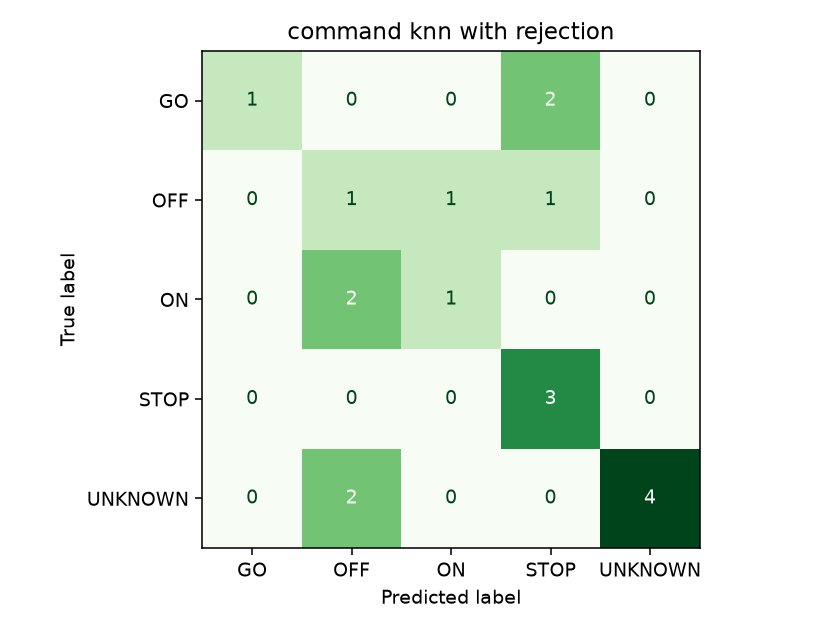

In [15]:
from evaluate import evaluate
evaluation_report = evaluate()
metrics = pd.read_csv(ROOT / 'results/metrics/test_metrics.csv')
display(metrics)
display(pd.read_csv(ROOT / 'results/metrics/hierarchy_metrics.csv'))
display(DisplayImage(filename=str(ROOT / 'results/confusion_matrices/command_knn_with_rejection.png'), width=550))

## 15. Run the Automated Tests
**Input:** the real modules, manifests, models and held-out samples. **Operation:** pytest checks routing, role permissions, every failure gate, UNKNOWN handling, sample separation, source consistency, all twelve classifiers and real fusion dimensions. **Output:** the actual test-run report.

Test doubles are used only for isolated control-flow cases. They are never presented as trained predictions. Data/model integration tests use actual files. A skipped integration test means unavailable evidence, not success.

In [16]:
completed = subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=ROOT,
                           text=True, capture_output=True)
print(completed.stdout)
if completed.returncode:
    print(completed.stderr)
assert completed.returncode == 0

...............................                                          [100%]
31 passed in 11.85s



## Next: The Local Application
Open **02_Streamlit_Demo.ipynb** or run `python -m streamlit run app.py` from this folder. The app loads saved models and held-out inputs.

Webcam mode means **Live Face + Offline Voice + Offline Fingerprint**. It requires a genuine new camera snapshot; a saved image is never substituted. Implementation does not prove a live camera demonstration.

Read **README.md** for commands and actual results; **DATASET_SOURCES.md** for provenance and manual recovery; **ORAL_DEFENSE.md** for English and Egyptian Arabic explanations.

**Limitations:** tiny virtual-identity experiment; near-duplicate portraits; only three fingerprint validation impressions; imperfect command/UNKNOWN recognition; no liveness, spoof resistance, real system control or production security claim. Team-collected voice data is **NOT SATISFIED**, since public recordings were requested. Preserve poor results rather than manufacturing a successful demonstration.